In [17]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [19]:
df = pd.read_csv('titanic_toy.csv')

In [20]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [10]:
df = df[['age','fare','family','survived']]

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [23]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [25]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [26]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [27]:
x_train.shape,x_test.shape

((712, 3), (179, 3))

In [28]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

In [29]:
mean_fare = x_train['Fare'].mean()
median_fare = x_train['Fare'].median()

In [30]:
x_train['Age_median'] = x_train['Age'].fillna(median_age)
x_train['Age_mean'] = x_train['Age'].fillna(mean_age)

x_train['Fare_median'] = x_train['Fare'].fillna(median_fare)
x_train['Fare_mean'] = x_train['Fare'].fillna(mean_fare)

In [31]:
x_train.sample()

,Age,Fare,Family,Age_median,Age_mean,Fare_median,Fare_mean
334,NaN,133.65,1,28.0,29.498846,133.65,133.65


<Axes: ylabel='Density'>

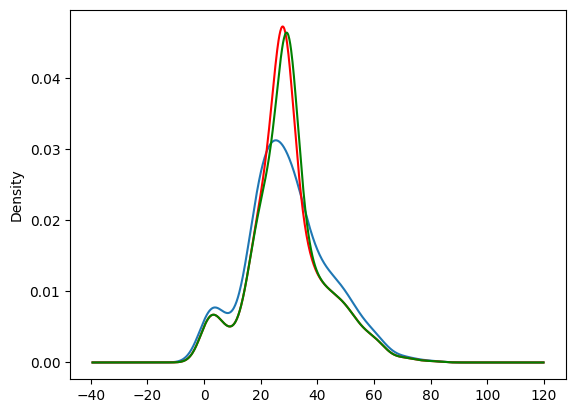

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111)

# Original variable distribution  
x_train['Age'].plot(kind = 'kde',ax = ax)

# Variable imputed with the median 
x_train['Age_median'].plot(kind='kde',ax=ax,color='red')

# Variable imputed with the mean 
x_train['Age_mean'].plot(kind='kde',ax=ax,color='green')

<Axes: >

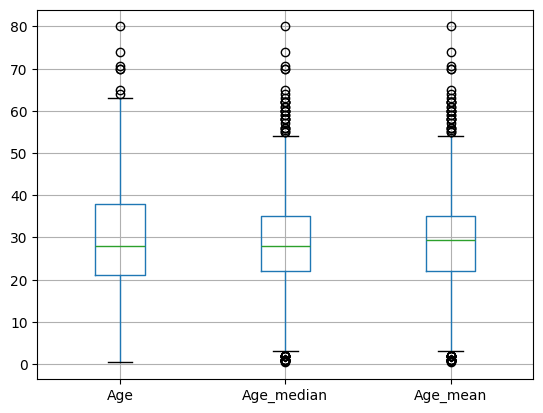

In [33]:
x_train[['Age','Age_median','Age_mean']].boxplot()

# Using Sklearn

In [34]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [35]:
impute1 = SimpleImputer(strategy='median')
impute2 = SimpleImputer(strategy='mean')

In [36]:
trf = ColumnTransformer([
    ('trf1',impute1,['Age']),
    ('trf2',impute2,['Fare'])
],remainder='passthrough')

In [37]:
trf.fit(x_train)

,transformers,"[('trf1', ...), ('trf2', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [42]:
trf.named_transformers_['trf1'].statistics_

array([28.75])

In [43]:
x_train = trf.transform(x_train)
x_test = trf.transform(x_test)

In [46]:
x_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 28.75  , 221.7792,   0.    ],
       [ 28.75  ,  25.925 ,   0.    ]], shape=(712, 3))